# CUQA code smell model (Java)

In [1]:
import json
import sys
import warnings
from pathlib import Path

TRAINING_DIR = Path.cwd()
if not (TRAINING_DIR / "train_model.py").exists():
    TRAINING_DIR = Path.cwd() / "training"
sys.path.insert(0, str(TRAINING_DIR))

import train_model as tm

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 3)

## 1. Dataset

In [2]:
# MLCQ samples matched to the downloaded source files
report = json.loads((tm.DATASET_DIR / "dataset_report.json").read_text())
print("MLCQ samples:", report["mlcq_samples_total"])
print("matched:", report["sample_status"]["matched"],
      "| file not available:", report["sample_status"]["source_unavailable"],
      "| parse failed:", report["sample_status"]["parse_failed"])

# same code in two repositories is kept only once
tables = {"class": tm.load_table("mlcq_classes.csv"), "method": tm.load_table("mlcq_methods.csv")}
features = {"class": list(tm.CLASS_FEATURES), "method": list(tm.METHOD_FEATURES)}
print("rows:", {k: len(t) for k, t in tables.items()}, "| features:", {k: len(v) for k, v in features.items()})

pd.DataFrame([
    {"smell": s.display_name, "entity": s.entity,
     "samples": int(tables[s.entity][f"label_{s.key}"].notna().sum()),
     "positive": int(tables[s.entity][f"label_{s.key}"].sum()),
     "positive %": 100 * tables[s.entity][f"label_{s.key}"].mean()}
    for s in tm.SMELLS
])

MLCQ samples: 4770
matched: 4277 | file not available: 478 | parse failed: 15


rows: {'class': 2106, 'method': 2167} | features: {'class': 49, 'method': 51}


,smell,entity,samples,positive,positive %
0,Long Method,method,2167,233,10.752
1,Feature Envy,method,2156,59,2.737
2,Blob (Large Class),class,2102,220,10.466
3,Data Class,class,2105,277,13.159


In [3]:
tables["method"][features["method"][:12]].describe().T[["mean", "50%", "max"]]

,mean,50%,max
loc,15.222,8.0,415.0
sloc,13.257,8.0,310.0
comment_lines,0.833,0.0,145.0
n_tokens,89.375,50.0,2030.0
n_identifiers,28.454,16.0,642.0
n_distinct_identifiers,14.169,10.0,154.0
n_operators,6.719,3.0,285.0
n_literals,3.409,1.0,281.0
n_statements,5.874,3.0,200.0
cyclomatic_complexity,3.007,2.0,79.0


## 2. Train / test split

In [4]:
# split by repository, so test projects are never seen in training
train_repos, test_repos = tm.split_repositories(*tables.values())
print(len(train_repos), "train repositories,", len(test_repos), "test repositories")
print("overlap:", len(train_repos & test_repos))

398 train repositories, 100 test repositories
overlap: 0


In [5]:
def smell_data(spec):
    table = tables[spec.entity]
    table = table[table[f"label_{spec.key}"].notna()].reset_index(drop=True)
    is_test = table["repository"].isin(test_repos).to_numpy()
    X = table[features[spec.entity]].to_numpy(dtype=float)
    y = table[f"label_{spec.key}"].to_numpy(dtype=int)
    g = table["repository"].to_numpy()
    return X[~is_test], y[~is_test], g[~is_test], X[is_test], y[is_test], g[is_test]

data = {s.key: smell_data(s) for s in tm.SMELLS}
pd.DataFrame([
    {"smell": s.display_name, "train": len(data[s.key][1]), "train positive": int(data[s.key][1].sum()),
     "test": len(data[s.key][4]), "test positive": int(data[s.key][4].sum())}
    for s in tm.SMELLS
])

,smell,train,train positive,test,test positive
0,Long Method,1813,189,354,44
1,Feature Envy,1803,47,353,12
2,Blob (Large Class),1723,176,379,44
3,Data Class,1726,221,379,56


## 3. Model comparison

In [6]:
# 5-fold CV grouped by repository, repeated 3 times, training repositories only
comparison_rows, gb_oof = [], {}
for spec in tm.SMELLS:
    X_tr, y_tr, g_tr = data[spec.key][:3]
    for name in tm.candidate_models(0):
        pr, roc, mean_oof = [], [], np.zeros(len(y_tr))
        for repeat in range(tm.CV_REPEATS):
            oof = tm.out_of_fold(lambda seed, n=name: tm.candidate_models(seed)[n],
                                 X_tr, y_tr, g_tr, seed=tm.RANDOM_SEED + repeat)
            pr.append(average_precision_score(y_tr, oof))
            roc.append(roc_auc_score(y_tr, oof))
            mean_oof += oof / tm.CV_REPEATS
        if name == "Gradient Boosting":
            gb_oof[spec.key] = mean_oof
        comparison_rows.append({"smell": spec.display_name, "model": name,
                                "PR-AUC": np.mean(pr), "PR-AUC std": np.std(pr),
                                "ROC-AUC": np.mean(roc), "best F1": tm.best_f1_threshold(y_tr, mean_oof)[1]})
pd.DataFrame(comparison_rows)

,smell,model,PR-AUC,PR-AUC std,ROC-AUC,best F1
0,Long Method,Logistic Regression,0.842,0.007,0.972,0.765
1,Long Method,Random Forest,0.853,0.006,0.979,0.770
2,Long Method,Gradient Boosting,0.854,0.009,0.980,0.776
3,Feature Envy,Logistic Regression,0.143,0.011,0.831,0.247
4,Feature Envy,Random Forest,0.167,0.010,0.889,0.304
5,Feature Envy,Gradient Boosting,0.160,0.030,0.876,0.289
6,Blob (Large Class),Logistic Regression,0.465,0.004,0.885,0.500
7,Blob (Large Class),Random Forest,0.527,0.007,0.905,0.547
8,Blob (Large Class),Gradient Boosting,0.519,0.006,0.900,0.530
9,Data Class,Logistic Regression,0.636,0.002,0.905,0.610


## 4. Threshold

In [7]:
# threshold = best F1 on the out-of-fold training predictions
# a smell is used only if its CV F1 is at least 0.50
thresholds, cv_rows = {}, []
for spec in tm.SMELLS:
    t, f1 = tm.best_f1_threshold(data[spec.key][1], gb_oof[spec.key])
    thresholds[spec.key] = t
    cv_rows.append({"smell": spec.display_name, "threshold": t, "CV F1": f1,
                    "used": f1 >= tm.MIN_CV_F1_TO_ENABLE})
pd.DataFrame(cv_rows)

,smell,threshold,CV F1,used
0,Long Method,0.504,0.776,True
1,Feature Envy,0.063,0.289,False
2,Blob (Large Class),0.248,0.530,True
3,Data Class,0.238,0.609,True


## 5. Test results

In [8]:
# final model on all training repositories, tested once on the test repositories
# 95% CI from bootstrap over repositories
results = {}
for spec in tm.SMELLS:
    X_tr, y_tr, g_tr, X_te, y_te, g_te = data[spec.key]
    model = tm.make_gradient_boosting().fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = proba >= thresholds[spec.key]
    results[spec.key] = {
        "model": model, "proba": proba, "pred": pred,
        "test": {**tm.threshold_metrics(y_te, pred), **tm.ranking_metrics(y_te, proba)},
        "ci": tm.cluster_bootstrap(y_te, pred, proba, g_te, tm.BOOTSTRAP_ITERATIONS, tm.RANDOM_SEED),
    }

ci = lambda r, k: f"[{r['ci'][k][0]:.2f}, {r['ci'][k][1]:.2f}]"
pd.DataFrame([
    {"smell": s.display_name, "precision": r["test"]["precision"], "recall": r["test"]["recall"],
     "F1": r["test"]["f1"], "F1 95% CI": ci(r, "f1"), "MCC": r["test"]["mcc"],
     "ROC-AUC": r["test"]["roc_auc"], "PR-AUC": r["test"]["pr_auc"],
     "TP": r["test"]["tp"], "FP": r["test"]["fp"], "FN": r["test"]["fn"], "TN": r["test"]["tn"]}
    for s, r in ((s, results[s.key]) for s in tm.SMELLS)
])

,smell,precision,recall,F1,F1 95% CI,MCC,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Long Method,0.829,0.659,0.734,"[0.62, 0.82]",0.707,0.982,0.902,29,6,15,304
1,Feature Envy,0.154,0.333,0.211,"[0.05, 0.38]",0.186,0.871,0.145,4,22,8,319
2,Blob (Large Class),0.458,0.614,0.524,"[0.39, 0.63]",0.458,0.904,0.574,27,32,17,303
3,Data Class,0.702,0.714,0.708,"[0.60, 0.79]",0.657,0.941,0.770,40,17,16,306


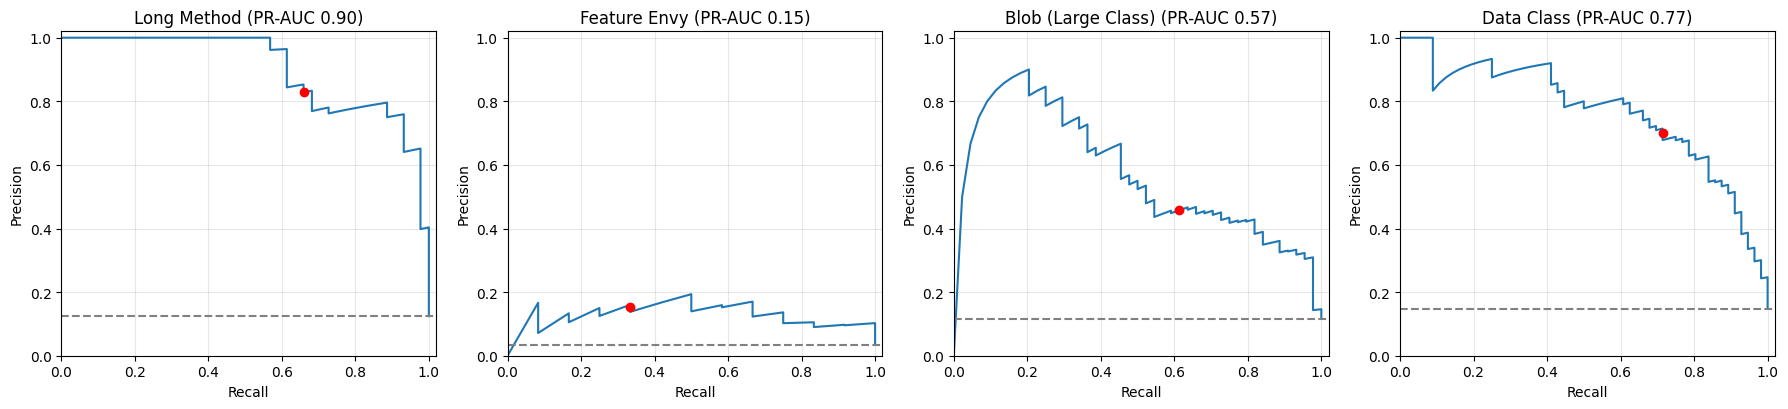

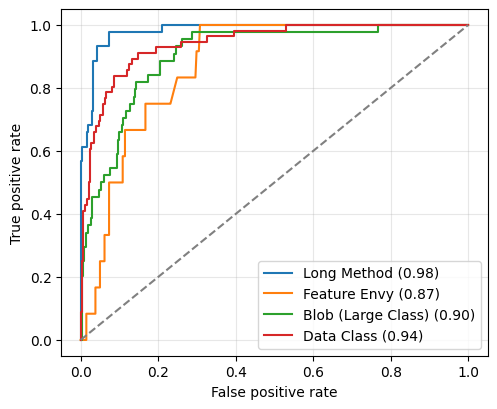

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, spec in zip(axes, tm.SMELLS):
    y_te, r = data[spec.key][4], results[spec.key]
    p, rc, _ = precision_recall_curve(y_te, r["proba"])
    ax.plot(rc, p)
    ax.axhline(y_te.mean(), linestyle="--", color="gray")
    ax.scatter([r["test"]["recall"]], [r["test"]["precision"]], color="red", zorder=3)
    ax.set_title(f"{spec.display_name} (PR-AUC {r['test']['pr_auc']:.2f})")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for spec in tm.SMELLS:
    fpr, tpr, _ = roc_curve(data[spec.key][4], results[spec.key]["proba"])
    ax.plot(fpr, tpr, label=f"{spec.display_name} ({results[spec.key]['test']['roc_auc']:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

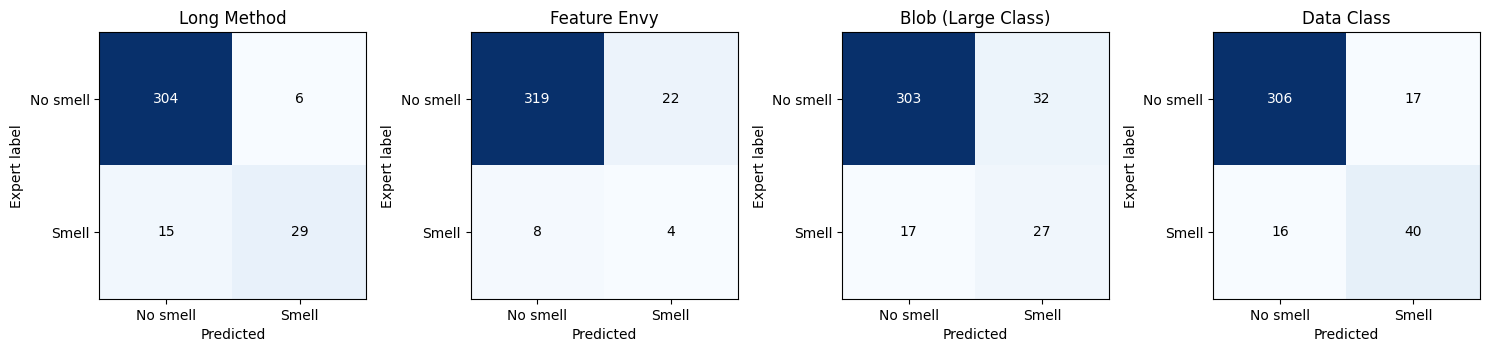

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, spec in zip(axes, tm.SMELLS):
    t = results[spec.key]["test"]
    m = np.array([[t["tn"], t["fp"]], [t["fn"], t["tp"]]])
    ax.imshow(m, cmap="Blues")
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > m.max() / 2 else "black")
    ax.set_xticks([0, 1], ["No smell", "Smell"]); ax.set_yticks([0, 1], ["No smell", "Smell"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Expert label"); ax.set_title(spec.display_name)
fig.tight_layout()
plt.show()

## 6. Baseline

In [11]:
# best single metric rule (metric >= t) found on the training data
# F1 difference CI uses the same bootstrap samples for both
baseline_rows = []
for spec in tm.SMELLS:
    X_tr, y_tr, g_tr, X_te, y_te, g_te = data[spec.key]
    rule = tm.best_single_metric_rule(X_tr, y_tr, features[spec.entity])
    single_pred = tm.apply_single_metric_rule(rule, X_te)
    diff = tm.paired_f1_difference(y_te, results[spec.key]["pred"], single_pred, g_te,
                                   tm.BOOTSTRAP_ITERATIONS, tm.RANDOM_SEED)
    baseline_rows.append({
        "smell": spec.display_name,
        "single metric": f"{rule['feature']} {rule['direction']} {rule['threshold']:g}",
        "single metric F1": tm.threshold_metrics(y_te, single_pred)["f1"],
        "model F1": results[spec.key]["test"]["f1"],
        "difference": diff["difference"],
        "95% CI": f"[{diff['ci95'][0]:+.2f}, {diff['ci95'][1]:+.2f}]",
    })
pd.DataFrame(baseline_rows)

,smell,single metric,single metric F1,model F1,difference,95% CI
0,Long Method,loc >= 30,0.750,0.734,-0.016,"[-0.12, +0.07]"
1,Feature Envy,n_calls_on_locals >= 7,0.263,0.211,-0.053,"[-0.21, +0.11]"
2,Blob (Large Class),sloc >= 156,0.515,0.524,0.009,"[-0.06, +0.09]"
3,Data Class,accessor_ratio >= 0.521739,0.571,0.708,0.137,"[+0.05, +0.23]"


## 7. Feature importance

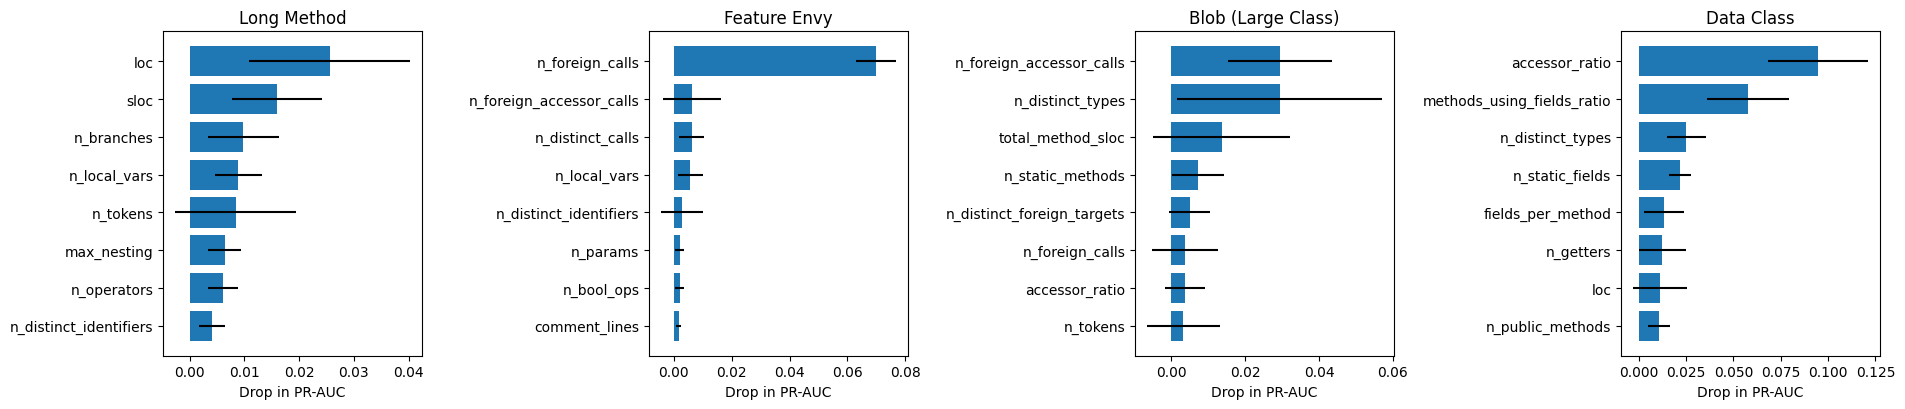

In [12]:
# drop in PR-AUC when one feature is shuffled (test repositories)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, spec in zip(axes, tm.SMELLS):
    X_te, y_te = data[spec.key][3], data[spec.key][4]
    perm = tm.permutation_importance(results[spec.key]["model"], X_te, y_te, scoring="average_precision",
                                     n_repeats=20, random_state=tm.RANDOM_SEED)
    order = np.argsort(-perm.importances_mean)[:8][::-1]
    names = features[spec.entity]
    ax.barh([names[i] for i in order], perm.importances_mean[order], xerr=perm.importances_std[order])
    ax.set_title(spec.display_name); ax.set_xlabel("Drop in PR-AUC")
fig.tight_layout()
plt.show()

## 8. Reviewer agreement

In [13]:
# agreement between MLCQ reviewers of the same sample
pd.DataFrame(tm.reviewer_agreement()).T

,review_pairs,observed_agreement,positive_agreement_f1,cohen_kappa
blob,2909.0,0.674,0.577,0.312
data class,2903.0,0.702,0.664,0.396
feature envy,1471.0,0.513,0.305,-0.071
long method,1495.0,0.787,0.809,0.567
